<a href="https://colab.research.google.com/github/Emma-Asoliya/cervical-screening-app/blob/main/Initial_Software.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pip show tensorflow

Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: dopamine_rl, tensorflow-text, tf_keras, ydf_tf


In [25]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
DATASET_ROOT = "/content/drive/MyDrive/Colposcopy_Data_In_Brief"

In [27]:
records = []
for category in ["01_Normal", "02_Abnormal"]:
  category_path = os.path.join(DATASET_ROOT, category)
  for patient_folder in os.listdir(category_path):
    patient_path = os.path.join(category_path, patient_folder)
    if not os.path.isdir(patient_path):
      continue
    for file in os.listdir(patient_path):
      if file.lower().endswith(".jpg"):
        records.append({
            "patient_id": patient_folder,
            "image_path": os.path.join(patient_path, file),
            "filename": file,
            "label_binary": "Normal" if category == "01_Normal" else "Abnormal"
        })
df = pd.DataFrame(records)
df.shape

(3372, 4)

label_binary
Normal      2149
Abnormal    1223
Name: count, dtype: int64


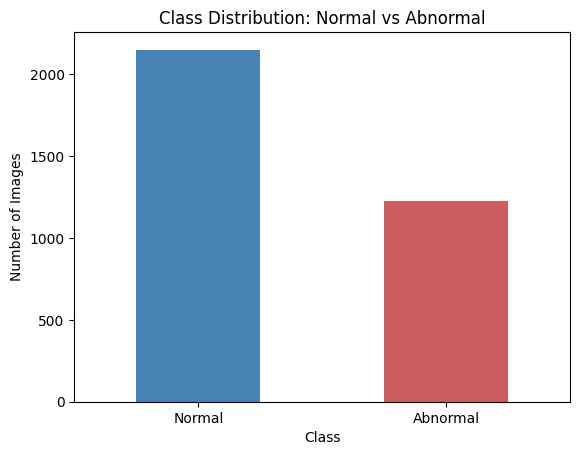

In [23]:
import matplotlib.pyplot as plt

class_counts = df["label_binary"].value_counts()
print(class_counts)

class_counts.plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Class Distribution: Normal vs Abnormal")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

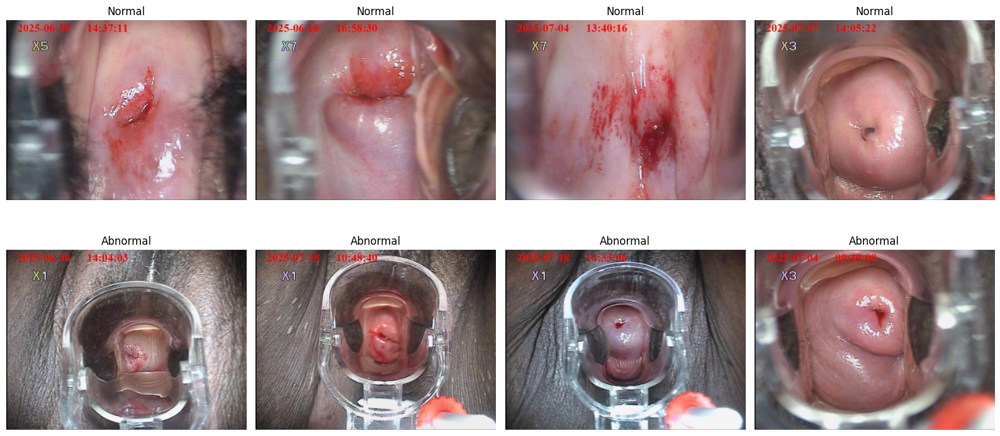

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, label in enumerate(["Normal", "Abnormal"]):
  sample_paths = df[df["label_binary"] == label]["image_path"].sample(4, random_state=42).tolist()
  for j, path in enumerate(sample_paths):
    img = Image.open(path)
    axes[i, j].imshow(img)
    axes[i, j].set_title(label)
    axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [28]:
from sklearn.model_selection import train_test_split

patient_df = df.groupby("patient_id")["label_binary"].first().reset_index()

train_patients, temp_patients = train_test_split(
    patient_df, test_size=0.30, stratify=patient_df["label_binary"], random_state=42
)

val_patients, test_patients = train_test_split(
    temp_patients, test_size=0.50, stratify=temp_patients["label_binary"], random_state=42
)

df["split"] = df["patient_id"].apply(
    lambda pid: "train" if pid in set(train_patients["patient_id"])
    else "val" if pid in set(val_patients["patient_id"])
    else "test"
)

df["split"].value_counts()

print("Patients appearing in both classes:",
      (df.groupby("patient_id")["label_binary"].nunique() > 1).sum())
print(df["split"].value_counts())

SPLIT_CSV = "/content/drive/MyDrive/cervical_app/split.csv"
os.makedirs(os.path.dirname(SPLIT_CSV), exist_ok=True)
df[["patient_id", "filename", "split"]].to_csv(SPLIT_CSV, index=False)

Patients appearing in both classes: 0
split
train    2351
test      513
val       508
Name: count, dtype: int64


In [29]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

def load_image(path, label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, IMG_SIZE)
  return tf.cast(img, tf.uint8), label

def preprocess(img, label):
  return tf.keras.applications.densenet.preprocess_input(tf.cast(img, tf.float32)), label

def augment_and_preprocess(img, label):
  img = data_augmentation(tf.cast(img, tf.float32), training=True)
  return tf.keras.applications.densenet.preprocess_input(img), label

def make_dataset(split_name, training=False):
  subset = df[df["split"] == split_name]
  paths = subset["image_path"].values
  labels = (subset["label_binary"] == "Abnormal").astype("float32").values
  ds = tf.data.Dataset.from_tensor_slices((paths, labels))
  ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
  if training:
    ds = ds.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)
  ds = ds.batch(BATCH_SIZE)
  ds = ds.map(augment_and_preprocess if training else preprocess, num_parallel_calls=AUTOTUNE)
  return ds.prefetch(AUTOTUNE)

train_ds = make_dataset("train", training=True)
val_ds = make_dataset("val")
test_ds = make_dataset("test")

for _, lbls in train_ds.take(3):
  print(f"Fraction abnormal in batch: {lbls.numpy().mean():.2f}")

Fraction abnormal in batch: 0.50
Fraction abnormal in batch: 0.44
Fraction abnormal in batch: 0.38


In [10]:
base_model = tf.keras.applications.DenseNet121(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,038,529 (26.85 MB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [16]:
from sklearn.utils.class_weight import compute_class_weight

def make_metrics():
  return ["accuracy",
          tf.keras.metrics.Precision(name="precision"),
          tf.keras.metrics.Recall(name="recall"),
          tf.keras.metrics.AUC(name="auc")]


train_labels = (df[df["split"] == "train"]["label_binary"] == "Abnormal").astype(int).values
cw = compute_class_weight("balanced", classes=np.unique(train_labels), y=train_labels)
class_weight_dict = dict(enumerate(cw))
print(class_weight_dict)

def make_callbacks():
  return [
      tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3,
                                       restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc",mode="max", factor=0.3,
                                           patience=2, verbose=1),
  ]

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy", metrics=make_metrics())
history = model.fit(train_ds, validation_data=val_ds, epochs=15,
                    class_weight=class_weight_dict, callbacks=make_callbacks())

{0: np.float64(0.7873409243134628), 1: np.float64(1.3700466200466201)}
Epoch 1/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 90s 878ms/step - accuracy: 0.5177 - auc: 0.5261 - loss: 0.7970 - precision: 0.3796 - recall: 0.5070 - val_accuracy: 0.6752 - val_auc: 0.6563 - val_loss: 0.6064 - val_precision: 0.6000 - val_recall: 0.1552 - learning_rate: 0.0010
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 28s 368ms/step - accuracy: 0.5466 - auc: 0.5584 - loss: 0.7486 - precision: 0.4063 - recall: 0.5256 - val_accuracy: 0.6614 - val_auc: 0.6562 - val_loss: 0.6240 - val_precision: 0.5069 - val_recall: 0.4195 - learning_rate: 0.0010
Epoch 3/15
73/74 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step - accuracy: 0.5505 - auc: 0.5737 - loss: 0.7371 - precision: 0.4282 - recall: 0.5834
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
74/74 ━━━━━━━━━━━━━━━━━━━━ 28s 372ms/step - accuracy: 0.5466 - auc: 0.5664 - loss: 0.7364 - precision: 0.4099 - recall: 0.5513 - val_accuracy: 0.6516 - val_auc: 0.6558 - val_loss: 0.

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-60]:
  layer.trainable = False
for layer in base_model.layers[-60:]:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=make_metrics())

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=make_callbacks()
)

Epoch 1/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 94s 848ms/step - accuracy: 0.5895 - auc: 0.6251 - loss: 0.6777 - precision: 0.4527 - recall: 0.5967 - val_accuracy: 0.6437 - val_auc: 0.6118 - val_loss: 0.6446 - val_precision: 0.4745 - val_recall: 0.3736 - learning_rate: 1.0000e-04
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 28s 368ms/step - accuracy: 0.5849 - auc: 0.6238 - loss: 0.6754 - precision: 0.4479 - recall: 0.5909 - val_accuracy: 0.6280 - val_auc: 0.6188 - val_loss: 0.6543 - val_precision: 0.4576 - val_recall: 0.4655 - learning_rate: 1.0000e-04
Epoch 3/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 27s 364ms/step - accuracy: 0.6044 - auc: 0.6499 - loss: 0.6584 - precision: 0.4677 - recall: 0.6072 - val_accuracy: 0.4783 - val_auc: 0.6259 - val_loss: 0.7438 - val_precision: 0.3836 - val_recall: 0.8621 - learning_rate: 1.0000e-04
Epoch 4/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 27s 364ms/step - accuracy: 0.6265 - auc: 0.6760 - loss: 0.6432 - precision: 0.4911 - recall: 0.6457 - val_accuracy: 0.4665 - val_auc: 0.6130 - val_lo

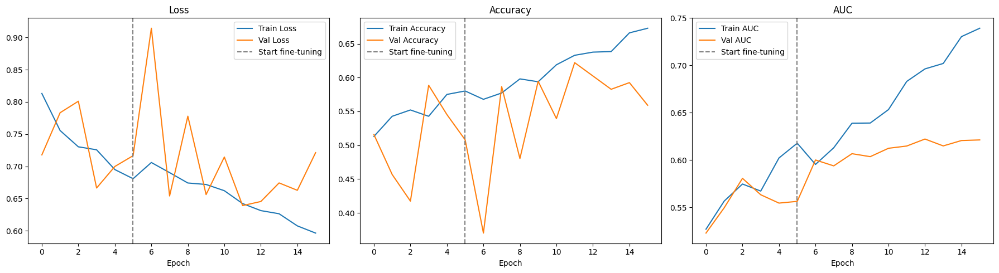

In [ ]:
def join(key):
    return history.history[key] + history_finetune.history[key]

n1 = len(history.history["loss"])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (k, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]):
    ax.plot(join(k), label=f"Train {title}")
    ax.plot(join("val_" + k), label=f"Val {title}")
    ax.axvline(n1 - 1, color="gray", linestyle="--", label="Start fine-tuning")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
test_results = model.evaluate(test_ds, return_dict=True)
print({k: round(v, 4) for k, v in test_results.items()})

17/17 ━━━━━━━━━━━━━━━━━━━━ 150s 9s/step - accuracy: 0.5731 - auc: 0.5590 - loss: 0.6820 - precision: 0.4157 - recall: 0.3613
{'accuracy': 0.5731, 'auc': 0.559, 'loss': 0.682, 'precision': 0.4157, 'recall': 0.3613}


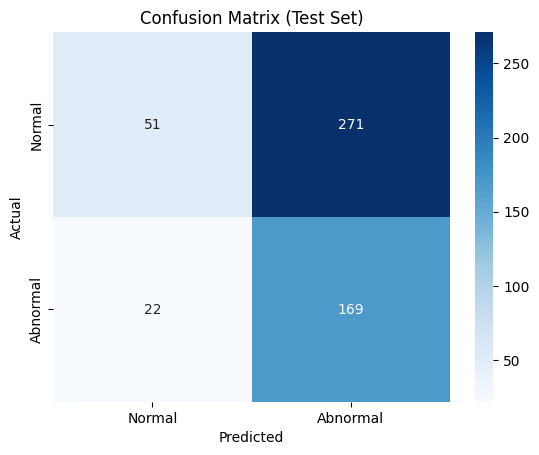

              precision    recall  f1-score   support

      Normal       0.70      0.16      0.26       322
    Abnormal       0.38      0.88      0.54       191

    accuracy                           0.43       513
   macro avg       0.54      0.52      0.40       513
weighted avg       0.58      0.43      0.36       513



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:
  preds = model.predict(images, verbose=0)
  y_true.extend(labels.numpy())
  y_pred.extend((preds > 0.5).astype(int).flatten())

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"], cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Test Set)")
plt.show()

print(classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"]))

['global_average_pooling2d', 'dropout', 'dense']


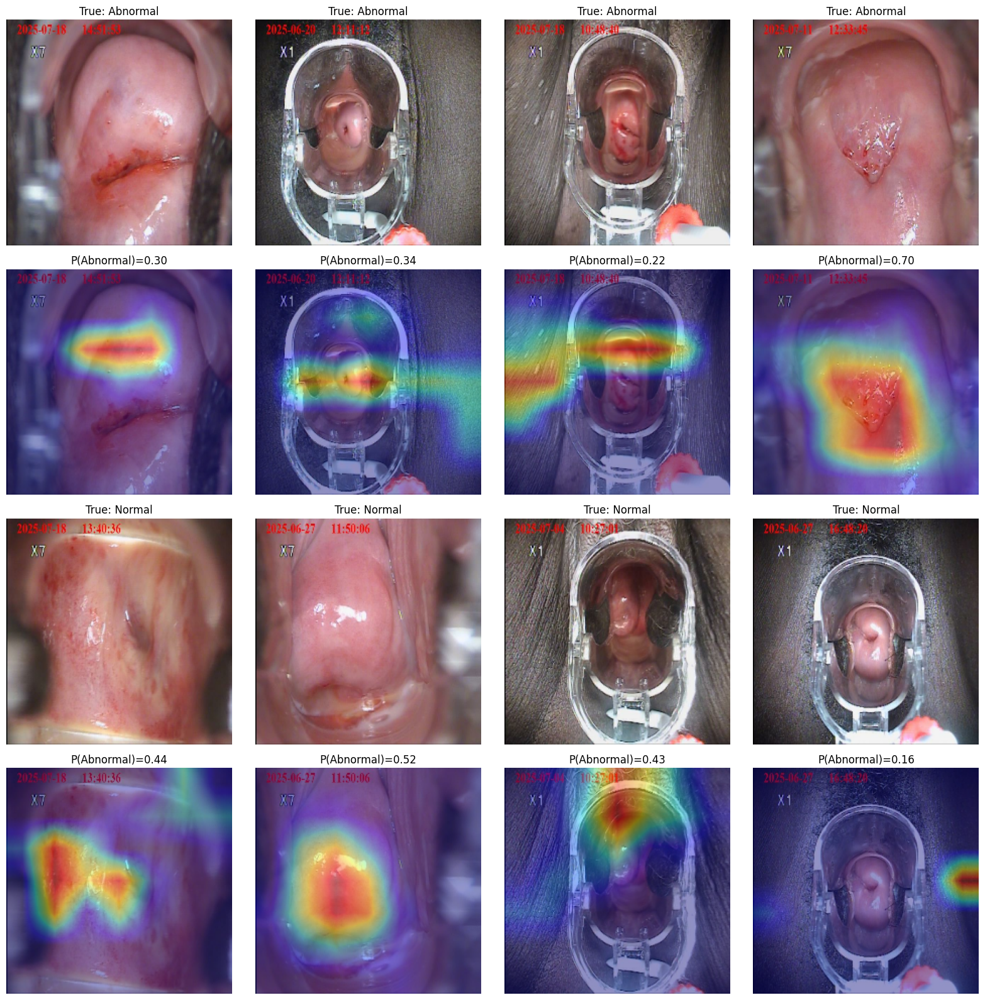

In [ ]:
import cv2
import matplotlib.pyplot as plt

last_conv_layer_name = "relu"
grad_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=base_model.get_layer(last_conv_layer_name).output
)

classifier_layers = [model.layers[-3], model.layers[-2], model.layers[-1]]
print([layer.name for layer in classifier_layers])

def make_gradcam_heatmap(img_array):
    with tf.GradientTape() as tape:
        conv_outputs = grad_model(img_array)
        tape.watch(conv_outputs)
        x = conv_outputs
        for layer in classifier_layers:
            x = layer(x)
        prediction = x[:, 0]

    grads = tape.gradient(prediction, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.squeeze(conv_outputs[0] @ pooled_grads[..., tf.newaxis])
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(prediction[0])

def get_gradcam_overlay(image_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img_display = img.numpy().astype("uint8")

    img_array = tf.keras.applications.densenet.preprocess_input(tf.cast(img, tf.float32))
    img_array = tf.expand_dims(img_array, axis=0)

    heatmap, score = make_gradcam_heatmap(img_array)

    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_colored = (plt.get_cmap("jet")(heatmap_resized)[:, :, :3] * 255).astype("uint8")
    overlay = cv2.addWeighted(img_display, 0.6, heatmap_colored, 0.4, 0)
    return img_display, heatmap_colored, overlay, score

test_df = df[df["split"] == "test"]
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for block, label in enumerate(["Abnormal", "Normal"]):
  rows = test_df[test_df["label_binary"] == label].sample(4, random_state=7)
  for j, (_, r) in enumerate(rows.iterrows()):
    original, _, overlay_img, score = get_gradcam_overlay(r["image_path"])
    axes[block*2, j].imshow(original); axes[block*2, j].set_title(f"True: {label}")
    axes[block*2+1, j].imshow(overlay_img); axes[block*2+1, j].set_title(f"P(Abnormal)={score:.2f}")
    axes[block*2, j].axis("off"); axes[block*2+1, j].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
MODEL_DIR = "/content/drive/MyDrive/cervical_app"
os.makedirs(MODEL_DIR, exist_ok=True)

model.save(f"{MODEL_DIR}/cervical_densenet121.keras")
print(os.listdir(MODEL_DIR))

['split.csv', 'cervical_densenet121.keras']


In [11]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

def report(ds, name="", m=None):
  m = m if m is not None else model
  y_true, y_prob = [], []
  for images, labels in ds:
      y_prob.extend(m.predict(images, verbose=0).flatten())
      y_true.extend(labels.numpy())
  y_true, y_prob = np.array(y_true), np.array(y_prob)
  y_pred = (y_prob > 0.5).astype(int)
  print(f"--- {name} ---")
  print("AUC:", round(roc_auc_score(y_true, y_prob), 3))
  print("Confusion matrix [rows=actual Normal/Abnormal, cols=predicted]:")
  print(confusion_matrix(y_true, y_pred))
  print(classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"]))
  return y_true, y_prob

_ = report(test_ds, "Current model, all images")

--- Current model, all images ---
AUC: 0.45
Confusion matrix [rows=actual Normal/Abnormal, cols=predicted]:
[[271  51]
 [171  20]]
              precision    recall  f1-score   support

      Normal       0.61      0.84      0.71       322
    Abnormal       0.28      0.10      0.15       191

    accuracy                           0.57       513
   macro avg       0.45      0.47      0.43       513
weighted avg       0.49      0.57      0.50       513



image_type
post     1700
pre      1669
other       3
Name: count, dtype: int64


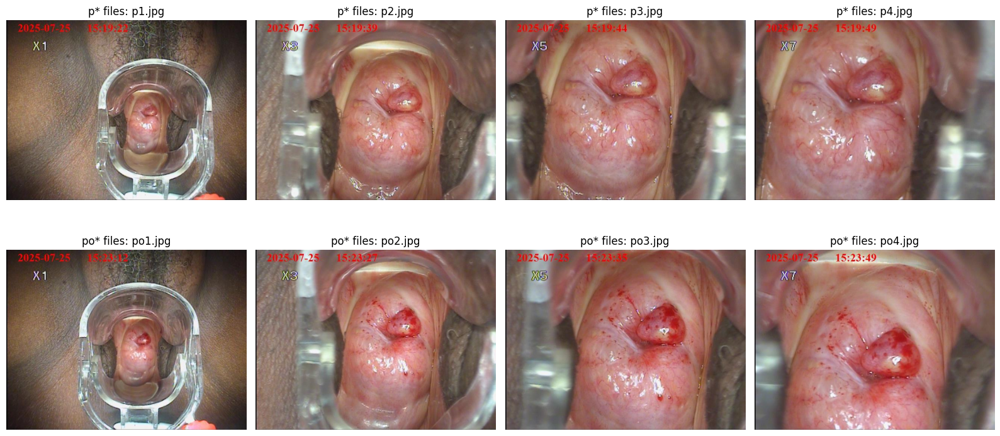

In [ ]:
df["image_type"] = (df["filename"].str.lower().str.extract(r"^([a-z]+)")[0]
                    .map({"p": "pre", "po": "post"}).fillna("other"))
print(df["image_type"].value_counts())

pid = df[df["label_binary"] == "Abnormal"]["patient_id"].iloc[0]
pat = df[df["patient_id"] == pid].sort_values("filename")
groups = [("p* files", pat[pat["image_type"] == "pre"]["image_path"].tolist()[:4]),
          ("po* files", pat[pat["image_type"] == "post"]["image_path"].tolist()[:4])]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for row, (title, paths) in enumerate(groups):
    for j, path in enumerate(paths):
        axes[row, j].imshow(Image.open(path))
        axes[row, j].set_title(f"{title}: {os.path.basename(path)}")
        axes[row, j].axis("off")
plt.tight_layout()
plt.show()

In [31]:
import hashlib

df["image_type"] = (df["filename"].str.lower().str.extract(r"^([a-z]+)")[0]
                    .map({"p": "pre", "po": "post"}).fillna("other"))

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df["image_path"].apply(md5)

conflict = df.groupby("md5")["image_type"].nunique()
bad_md5 = set(conflict[conflict > 1].index)
print("Duplicate groups with conflicting pre/post label:", len(bad_md5))
df.loc[df["md5"].isin(bad_md5), "image_type"] = "ambiguous"

df["_len"] = df["filename"].str.len()
df = (df.sort_values(["patient_id", "md5", "_len", "filename"])
        .drop_duplicates(["patient_id", "md5"], keep="first")
        .drop(columns="_len").reset_index(drop=True))

print("Images after dedupe:", len(df), "| patients:", df["patient_id"].nunique())
print(df["image_type"].value_counts())
print(df["split"].value_counts())

Duplicate groups with conflicting pre/post label: 10
Images after dedupe: 3321 | patients: 332
image_type
post         1671
pre          1639
ambiguous      10
other           1
Name: count, dtype: int64
split
train    2315
test      510
val       496
Name: count, dtype: int64


In [34]:
feat_net = tf.keras.applications.DenseNet121(include_top=False, weights="imagenet",
                                             pooling="avg", input_shape=(224, 224, 3))
feat_ds = (tf.data.Dataset.from_tensor_slices((df["image_path"].values, np.zeros(len(df), "float32")))
          .map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
          .map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
feats = feat_net.predict(feat_ds, verbose=1)
assert len(feats) == len(df), "features and df are misaligned"
print(feats.shape)
np.save("/content/drive/MyDrive/cervical_app/densenet121_features.npy", feats)
df[["patient_id", "filename", "label_binary", "image_type"]].to_csv(
    "/content/drive/MyDrive/cervical_app/features_index.csv", index=False)

104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 262ms/step
(3321, 1024)


In [35]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

y_all = (df["label_binary"] == "Abnormal").astype(int).values
g_all = df["patient_id"].values

def cv_eval(mask, name, C=0.01, seed=42):
    X, y, g = feats[mask], y_all[mask], g_all[mask]
    oof, fold_aucs = np.zeros(len(y)), []
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X, y, g):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
        clf.fit(X[tr], y[tr])
        oof[te] = clf.predict_proba(X[te])[:, 1]
        fold_aucs.append(roc_auc_score(y[te], oof[te]))
    pat = pd.DataFrame({"patient_id": g, "y": y, "p": oof}).groupby("patient_id").agg(y=("y", "first"), p=("p", "mean"))
    rng, boots = np.random.default_rng(0), []
    for _ in range(1000):
        s = pat.sample(len(pat), replace=True, random_state=int(rng.integers(1e9)))
        if s["y"].nunique() == 2:
            boots.append(roc_auc_score(s["y"], s["p"]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"{name:15s} n_img={mask.sum()} | image AUC {roc_auc_score(y, oof):.3f} | "
          f"patient AUC {roc_auc_score(pat['y'], pat['p']):.3f} (95% CI {lo:.2f}-{hi:.2f}, "
          f"{len(pat)} patients) | folds {np.round(fold_aucs, 2)}")

cv_eval(np.ones(len(df), bool), "All images")
cv_eval((df["image_type"] == "post").values, "Post-acid only")
cv_eval((df["image_type"] == "pre").values, "Pre-acid only")

All images      n_img=3321 | image AUC 0.556 | patient AUC 0.591 (95% CI 0.53-0.65, 332 patients) | folds [0.52 0.61 0.53 0.54 0.61]
Post-acid only  n_img=1671 | image AUC 0.534 | patient AUC 0.545 (95% CI 0.48-0.61, 332 patients) | folds [0.49 0.48 0.55 0.54 0.63]
Pre-acid only   n_img=1639 | image AUC 0.560 | patient AUC 0.589 (95% CI 0.53-0.65, 332 patients) | folds [0.52 0.57 0.59 0.57 0.55]


In [36]:
from PIL import Image

meta = []
for p in df["image_path"]:
    with Image.open(p) as im:
        w, h = im.size
        small = np.asarray(im.convert("RGB").resize((32, 24)), dtype=np.float32)
    meta.append([w, h, os.path.getsize(p), *small.mean(axis=(0, 1))])
meta = np.array(meta)

meta_df = pd.DataFrame(meta, columns=["w", "h", "bytes", "R", "G", "B"])
meta_df["label"] = df["label_binary"].values
meta_df["res"] = meta_df["w"].astype(int).astype(str) + "x" + meta_df["h"].astype(int).astype(str)

print(meta_df.groupby("label")[["w", "h", "bytes", "R", "G", "B"]].mean().round(1))
ct = pd.crosstab(meta_df["res"], meta_df["label"])
print(ct.loc[ct.sum(axis=1).sort_values(ascending=False).index].head(8))

feats_backup = feats
feats = meta
cv_eval(np.ones(len(df), bool), "Metadata only")
feats = feats_backup

              w      h    bytes      R      G      B
label                                               
Abnormal  640.0  480.0  35419.6  138.1  105.9  106.1
Normal    640.0  480.0  34853.7  137.7  106.8  108.0
label    Abnormal  Normal
res                      
640x480      1211    2110
Metadata only   n_img=3321 | image AUC 0.561 | patient AUC 0.588 (95% CI 0.53-0.65, 332 patients) | folds [0.54 0.51 0.61 0.61 0.6 ]


In [37]:
import re

for c in ["bytes", "R", "G", "B"]:
    print(c, "single-feature image AUC:", round(roc_auc_score(y_all, meta_df[c]), 3))

d = df[df["image_type"].isin(["pre", "post"])].copy()
d["key"] = (d["filename"].str.lower().str.replace(".jpg", "", regex=False)
            .str.replace(r"\s*\(\d+\)", "", regex=True)
            .str.replace(r"^po", "p", regex=True))
d["row"] = d.index

pre  = d[d.image_type == "pre"].drop_duplicates(["patient_id", "key"]).set_index(["patient_id", "key"])["row"]
post = d[d.image_type == "post"].drop_duplicates(["patient_id", "key"]).set_index(["patient_id", "key"])["row"]
pairs = pd.concat([pre.rename("pre"), post.rename("post")], axis=1, join="inner")
print("matched pairs:", len(pairs), "| patients:", pairs.index.get_level_values(0).nunique())

pi, po = pairs["pre"].values, pairs["post"].values
feats_b, y_b, g_b = feats, y_all, g_all
feats = feats_b[po] - feats_b[pi]
y_all, g_all = y_b[po], g_b[po]
cv_eval(np.ones(len(pairs), bool), "Post minus pre")
feats, y_all, g_all = feats_b, y_b, g_b

bytes single-feature image AUC: 0.539
R single-feature image AUC: 0.514
G single-feature image AUC: 0.463
B single-feature image AUC: 0.435
matched pairs: 1402 | patients: 332
Post minus pre  n_img=1402 | image AUC 0.512 | patient AUC 0.532 (95% CI 0.47-0.60, 332 patients) | folds [0.53 0.53 0.49 0.49 0.52]


In [38]:
df["pid_num"] = df["patient_id"].str.extract(r"(\d+)")[0].astype(int)
pat = df.groupby("patient_id").agg(pid=("pid_num", "first"), y=("label_binary", "first")).reset_index()
pat["y"] = (pat["y"] == "Abnormal").astype(int)

print("Patient-ID-only AUC:", round(roc_auc_score(pat["y"], pat["pid"]), 3))

pat["bin"] = pd.qcut(pat["pid"], 6)
print(pat.groupby("bin", observed=True)["y"].agg(["mean", "count"]).round(2))

meta_df["pid"] = df["pid_num"].values
print(meta_df[["pid", "R", "G", "B", "bytes"]].corr()["pid"].round(3))

meta_df["bin"] = pd.qcut(meta_df["pid"], 6)
for b, g in meta_df.groupby("bin", observed=True):
    yy = (g["label"] == "Abnormal").astype(int)
    print(b, "B AUC:", round(roc_auc_score(yy, g["B"]), 3))

Patient-ID-only AUC: 0.48
                    mean  count
bin                            
(0.999, 57.167]     0.45     56
(57.167, 113.333]   0.33     55
(113.333, 169.5]    0.35     55
(169.5, 224.667]    0.36     55
(224.667, 286.833]  0.35     55
(286.833, 345.0]    0.38     56
pid      1.000
R        0.167
G        0.109
B        0.141
bytes   -0.067
Name: pid, dtype: float64
(0.999, 60.0] B AUC: 0.384
(60.0, 113.0] B AUC: 0.478
(113.0, 175.0] B AUC: 0.43
(175.0, 233.0] B AUC: 0.38
(233.0, 289.0] B AUC: 0.486
(289.0, 345.0] B AUC: 0.484


In [39]:
def cv_agg(mask, name, C=0.01, seed=42):
    X, y, g = feats[mask], y_all[mask], g_all[mask]
    oof = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X, y, g):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(C=C, class_weight="balanced", max_iter=2000))
        clf.fit(X[tr], y[tr])
        oof[te] = clf.predict_proba(X[te])[:, 1]
    d = pd.DataFrame({"g": g, "y": y, "p": oof})
    y_pat = d.groupby("g")["y"].first()
    aggs = {
        "mean":      d.groupby("g")["p"].mean(),
        "median":    d.groupby("g")["p"].median(),
        "max":       d.groupby("g")["p"].max(),
        "top3 mean": d.groupby("g")["p"].apply(lambda s: s.nlargest(3).mean()),
    }
    print(f"{name:18s}", {k: round(roc_auc_score(y_pat, v.loc[y_pat.index]), 3) for k, v in aggs.items()})

all_rows = np.ones(len(df), bool)
cv_agg(all_rows, "DenseNet features")

feats_backup = feats
feats = meta
cv_agg(all_rows, "Colour/size only")
feats = feats_backup

DenseNet features  {'mean': np.float64(0.591), 'median': np.float64(0.594), 'max': np.float64(0.555), 'top3 mean': np.float64(0.568)}
Colour/size only   {'mean': np.float64(0.588), 'median': np.float64(0.579), 'max': np.float64(0.554), 'top3 mean': np.float64(0.576)}


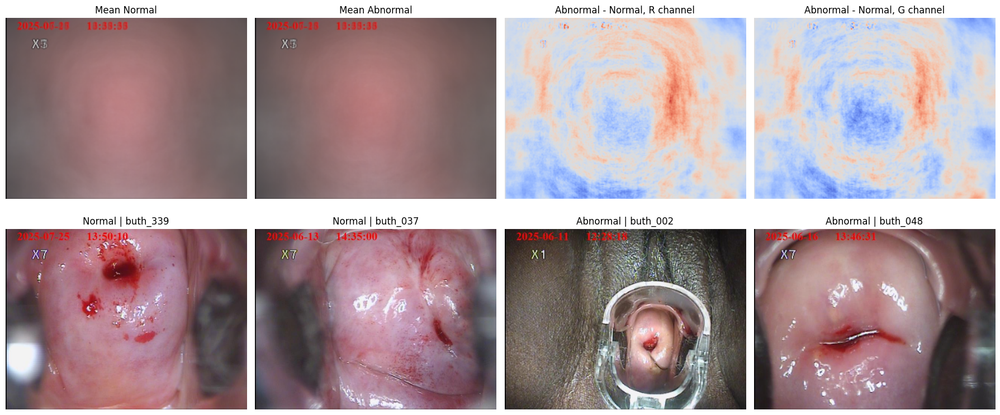

Max abs mean difference (0-255 scale): 14.98


In [40]:
from PIL import Image

def mean_image(paths, n=400, seed=0):
    paths = pd.Series(paths).sample(min(n, len(paths)), random_state=seed)
    acc = np.zeros((240, 320, 3), np.float64)
    for p in paths:
        with Image.open(p) as im:
            acc += np.asarray(im.convert("RGB").resize((320, 240)), dtype=np.float64)
    return acc / len(paths)

mean_ab = mean_image(df[df.label_binary == "Abnormal"]["image_path"])
mean_no = mean_image(df[df.label_binary == "Normal"]["image_path"])
diff = mean_ab - mean_no

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes[0, 0].imshow(mean_no.astype("uint8")); axes[0, 0].set_title("Mean Normal")
axes[0, 1].imshow(mean_ab.astype("uint8")); axes[0, 1].set_title("Mean Abnormal")
lim = np.abs(diff).max()
for k, ch in enumerate("RGB"):
    im_ = axes[0, 2 + k // 2].imshow(diff[:, :, k], cmap="coolwarm", vmin=-lim, vmax=lim) if k < 2 else None
axes[0, 2].set_title("Abnormal - Normal, R channel"); axes[0, 3].set_title("Abnormal - Normal, G channel")
axes[0, 2].imshow(diff[:, :, 0], cmap="coolwarm", vmin=-lim, vmax=lim)
axes[0, 3].imshow(diff[:, :, 1], cmap="coolwarm", vmin=-lim, vmax=lim)
sample = df[df.image_type == "post"].sample(4, random_state=3)
for ax, (_, r) in zip(axes[1], sample.iterrows()):
    ax.imshow(Image.open(r["image_path"])); ax.set_title(f"{r['label_binary']} | {r['patient_id']}")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()
print("Max abs mean difference (0-255 scale):", round(float(lim), 2))

In [17]:
def make_dataset(split_name, training=False, only_post=False):
    subset = df[df["split"] == split_name]
    if only_post:
        subset = subset[subset["image_type"] == "post"]
    paths = subset["image_path"].values
    labels = (subset["label_binary"] == "Abnormal").astype("float32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths), seed=42, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.map(augment_and_preprocess if training else preprocess, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds_post = make_dataset("train", training=True, only_post=True)
val_ds_post = make_dataset("val", only_post=True)
test_ds_post = make_dataset("test", only_post=True)

def build_model():
    base = tf.keras.applications.DenseNet121(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return base, tf.keras.Model(inputs, outputs)

lab = (df[(df["split"] == "train") & (df["image_type"] == "post")]["label_binary"] == "Abnormal").astype(int).values
class_weight_post = dict(enumerate(compute_class_weight("balanced", classes=np.unique(lab), y=lab)))

base_post, model_post = build_model()
model_post.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=make_metrics())
history_post = model_post.fit(train_ds_post, validation_data=val_ds_post, epochs=15,
                              class_weight=class_weight_post, callbacks=make_callbacks())

base_post.trainable = True
for layer in base_post.layers[:-60]:
    layer.trainable = False
for layer in base_post.layers[-60:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model_post.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="binary_crossentropy", metrics=make_metrics())
history_post_ft = model_post.fit(train_ds_post, validation_data=val_ds_post, epochs=15,
                                 class_weight=class_weight_post, callbacks=make_callbacks())

_ = report(test_ds_post, "Post-acid images only", m=model_post)

Epoch 1/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.5382 - auc: 0.5527 - loss: 0.8042 - precision: 0.4016 - recall: 0.5758 - val_accuracy: 0.5117 - val_auc: 0.4956 - val_loss: 0.7237 - val_precision: 0.3143 - val_recall: 0.3837 - learning_rate: 0.0010
Epoch 2/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 370ms/step - accuracy: 0.5206 - auc: 0.5441 - loss: 0.7725 - precision: 0.3750 - recall: 0.4965 - val_accuracy: 0.5195 - val_auc: 0.5185 - val_loss: 0.7382 - val_precision: 0.3669 - val_recall: 0.5930 - learning_rate: 0.0010
Epoch 3/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 362ms/step - accuracy: 0.5449 - auc: 0.5458 - loss: 0.7748 - precision: 0.4000 - recall: 0.5268 - val_accuracy: 0.5352 - val_auc: 0.5456 - val_loss: 0.7243 - val_precision: 0.3846 - val_recall: 0.6395 - learning_rate: 0.0010
Epoch 4/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 360ms/step - accuracy: 0.5491 - auc: 0.5620 - loss: 0.7596 - precision: 0.4066 - recall: 0.5478 - val_accuracy: 0.5820 - val_auc: 0.5758 - val_loss: 0.6913 - va

In [ ]:
import json, datetime

SEED =42
tf.keras.utils.set_random_seed(SEED)

USE_POST_ONLY = False
RUN_NAME = "baseline_cnn" + ("post_only" if USE_POST_ONLY else "all_images")

if USE_POST_ONLY:
  TRAIN, VAL, TEST, CW = train_ds_post, val_ds_post, test_ds_post, class_weight_post
else:
  TRAIN, VAL, TEST, CW = train_ds, val_ds, test_ds, class_weight_dict

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
EXP_DIR = f"/content/drive/MyDrive/cervical_app/experiments/{RUN_NAME}_{stamp}"
os.makedirs(EXP_DIR, exist_ok=True)
print("Saving this experiment to :", EXP_DIR)

Saving this experiment to : /content/drive/MyDrive/cervical_app/experiments/baseline_cnnall_images_20261015_2107


In [ ]:
def build_baseline_cnn():
  inputs = tf.keras.Input(shape=(224, 224, 3))
  x = tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same")(inputs)
  x = tf.keras.layers.MaxPooling2D()(x)
  x = tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same")(x)
  x = tf.keras.layers.MaxPooling2D()(x)
  x = tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same")(x)
  x = tf.keras.layers.MaxPooling2D()(x)
  x = tf.keras.layers.GlobalAveragePooling2D()(x)
  x = tf.keras.layers.Dropout(0.3)(x)
  outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
  return tf.keras.Model(inputs, outputs, name="baseline_cnn")

baseline_model = build_baseline_cnn()
baseline_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                       loss="binary_crossentropy", metrics=make_metrics())
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,649 (92.38 KB)

 Trainable params: 23,649 (92.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.3, patience=3, verbose=1),
    tf.keras.callbacks.CSVLogger(f"{EXP_DIR}/training_log.csv")
]
history_base = baseline_model.fit(TRAIN, validation_data=VAL, epochs=30,
                                  class_weight=CW, callbacks=callbacks)

Epoch 1/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 45s 412ms/step - accuracy: 0.4717 - auc: 0.5189 - loss: 0.6943 - precision: 0.3752 - recall: 0.6725 - val_accuracy: 0.6575 - val_auc: 0.5696 - val_loss: 0.6720 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 26s 342ms/step - accuracy: 0.5393 - auc: 0.5360 - loss: 0.6912 - precision: 0.3982 - recall: 0.5128 - val_accuracy: 0.5531 - val_auc: 0.5728 - val_loss: 0.6858 - val_precision: 0.3779 - val_recall: 0.4713 - learning_rate: 0.0010
Epoch 3/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 25s 333ms/step - accuracy: 0.5415 - auc: 0.5511 - loss: 0.6904 - precision: 0.4079 - recall: 0.5676 - val_accuracy: 0.6319 - val_auc: 0.5649 - val_loss: 0.6691 - val_precision: 0.3333 - val_recall: 0.0747 - learning_rate: 0.0010
Epoch 4/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 25s 337ms/step - accuracy: 0.5402 - auc: 0.5414 - loss: 0.6915 - precision: 0.3912 - recall: 0.4674 - val_accuracy: 0.6319 - val_auc: 0.5761 - val_loss: 

Test AUC (image level): 0.591
Test AUC (patient level, n = 50 ): 0.61 | accuracy: 0.62
[[294  28]
 [164  27]]
              precision    recall  f1-score   support

      Normal       0.64      0.91      0.75       322
    Abnormal       0.49      0.14      0.22       191

    accuracy                           0.63       513
   macro avg       0.57      0.53      0.49       513
weighted avg       0.59      0.63      0.55       513



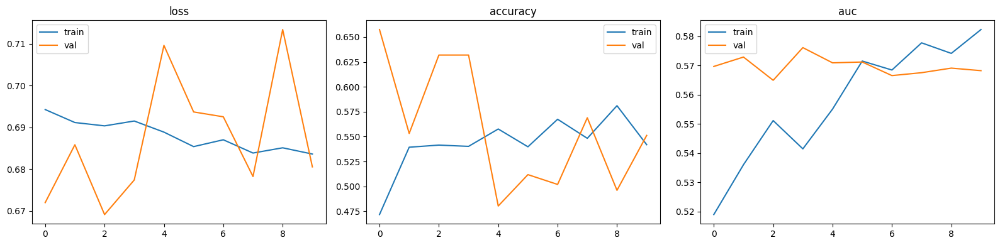

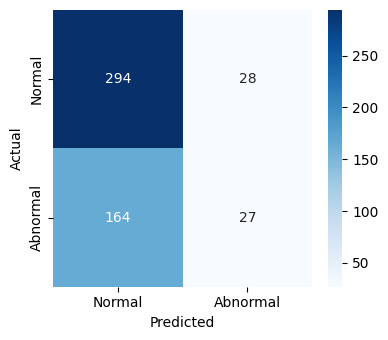

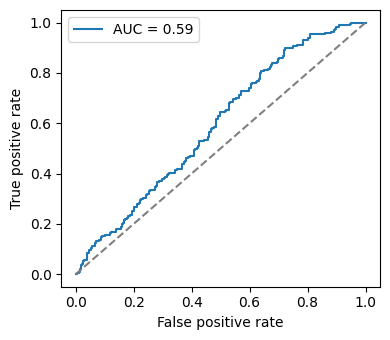

Saved: ['baseline_cnn.keras', 'config.json', 'confusion_matrix.png', 'history.json', 'model_summary.txt', 'roc_curve.png', 'split_assignments.csv', 'test_metrics.json', 'test_predictions.csv', 'training_curves.png', 'training_log.csv']


In [ ]:
import platform, sklearn
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

# 1. Predict on the test set
y_true, y_prob = [], []
for images, labels in TEST:
    y_prob.extend(baseline_model.predict(images, verbose=0).flatten())
    y_true.extend(labels.numpy())
y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)
y_pred = (y_prob > 0.5).astype(int)

# 2. Image-level and patient-level metrics
auc = roc_auc_score(y_true, y_prob)
conf = confusion_matrix(y_true, y_pred)
rep = classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"], output_dict=True)

test_df = df[df["split"] == "test"].copy()
if USE_POST_ONLY:
    test_df = test_df[test_df["image_type"] == "post"]
assert len(test_df) == len(y_prob)
test_df["y_true"], test_df["y_prob"] = y_true, y_prob
pat = test_df.groupby("patient_id").agg(y_true=("y_true", "first"), y_prob=("y_prob", "mean"))
pat_auc = roc_auc_score(pat["y_true"], pat["y_prob"])
pat_acc = float(((pat["y_prob"] > 0.5).astype(int) == pat["y_true"]).mean())

print("Test AUC (image level):", round(auc, 3))
print("Test AUC (patient level, n =", len(pat), "):", round(pat_auc, 3), "| accuracy:", round(pat_acc, 3))
print(conf)
print(classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"]))

# 3. Save metrics, predictions and the exact split
json.dump({"test_auc": float(auc), "confusion_matrix": conf.tolist(), "classification_report": rep,
           "patient_level_auc": float(pat_auc), "patient_level_accuracy": pat_acc,
           "n_test_images": int(len(y_true)), "n_test_patients": int(len(pat))},
          open(f"{EXP_DIR}/test_metrics.json", "w"), indent=2)
test_df[["patient_id", "filename", "label_binary", "y_true", "y_prob"]].to_csv(f"{EXP_DIR}/test_predictions.csv", index=False)
split_cols = [c for c in ["patient_id", "filename", "label_binary", "image_type", "split"] if c in df.columns]
df[split_cols].to_csv(f"{EXP_DIR}/split_assignments.csv", index=False)

# 4. Save config, history, model
json.dump({"run_name": RUN_NAME, "timestamp": stamp, "seed": SEED,
           "data": "post-acid only" if USE_POST_ONLY else "all images",
           "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE, "max_epochs": 30,
           "epochs_run": len(history_base.history["loss"]),
           "optimizer": "Adam, lr=1e-3 with ReduceLROnPlateau",
           "early_stopping": "val_auc, patience 6, restore best weights",
           "architecture": "3x (Conv2D 16/32/64 + MaxPool) + GAP + Dropout 0.3 + Dense(1, sigmoid)",
           "parameters": int(baseline_model.count_params()),
           "class_weights": {int(k): float(v) for k, v in CW.items()},
           "preprocessing": "densenet.preprocess_input",
           "augmentation": "flip h+v, rotation 0.1, zoom 0.1, contrast 0.1 (train only)",
           "split_counts_images": {k: int(v) for k, v in df["split"].value_counts().items()},
           "versions": {"python": platform.python_version(), "tensorflow": tf.__version__,
                        "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__}},
          open(f"{EXP_DIR}/config.json", "w"), indent=2, default=str)
json.dump({k: [float(v) for v in vals] for k, vals in history_base.history.items()},
          open(f"{EXP_DIR}/history.json", "w"), indent=2)
baseline_model.save(f"{EXP_DIR}/baseline_cnn.keras")
lines = []
baseline_model.summary(print_fn=lambda l: lines.append(l))
open(f"{EXP_DIR}/model_summary.txt", "w").write("\n".join(lines))

# 5. Save plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ["loss", "accuracy", "auc"]):
    ax.plot(history_base.history[m], label="train")
    ax.plot(history_base.history["val_" + m], label="val")
    ax.set_title(m); ax.legend()
plt.tight_layout(); plt.savefig(f"{EXP_DIR}/training_curves.png", dpi=150); plt.show()

plt.figure(figsize=(4, 3.5))
sns.heatmap(conf, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout()
plt.savefig(f"{EXP_DIR}/confusion_matrix.png", dpi=150); plt.show()

fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(4, 3.5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}"); plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend(); plt.tight_layout()
plt.savefig(f"{EXP_DIR}/roc_curve.png", dpi=150); plt.show()

print("Saved:", sorted(os.listdir(EXP_DIR)))

In [18]:
conflict = df.groupby("md5")["image_type"].nunique()
bad_md5 = set(conflict[conflict > 1].index)
print("Duplicate groups with conflicting pre/post label:", len(bad_md5))
df.loc[df["md5"].isin(bad_md5), "image_type"] = "ambiguous"

df["_len"] = df["filename"].str.len()
df = (df.sort_values(["patient_id", "md5", "_len", "filename"])
        .drop_duplicates(["patient_id", "md5"], keep="first")
        .drop(columns="_len").reset_index(drop=True))
print("Images after dedupe:", len(df), "| patients:", df["patient_id"].nunique())
print(df["image_type"].value_counts())

Duplicate groups with conflicting pre/post label: 10
Images after dedupe: 3321 | patients: 332
image_type
post         1671
pre          1639
ambiguous      10
other           1
Name: count, dtype: int64
